In [1]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

Imagen del mandril a grises:

In [3]:
img = cv2.imread('images/mandril.jpg')
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

TAREA 1: Realiza la cuenta de píxeles blancos por filas (en lugar de por columnas). Determina el valor máximo de píxeles blancos para filas, maxfil, mostrando el número de filas y sus respectivas posiciones, con un número de píxeles blancos mayor o igual que 0.90*maxfil. Resalta con alguna primitiva gráfica en la imagen de Canny las filas que cumplen dicha condición.

Máximo nº de píxeles blancos por fila: 220.0
Filas >= 90% del máximo (198.0):
POS   |  VALUE
----------------
6     |  203.0
12    |  220.0
15    |  204.0
20    |  200.0
21    |  201.0
88    |  199.0
100   |  212.0


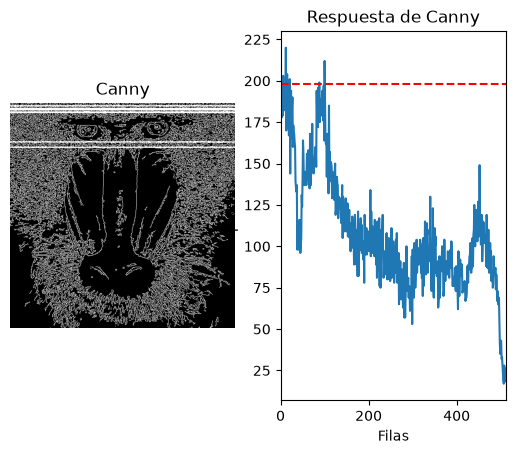

In [14]:

canny = cv2.Canny(gris, 100, 200)

row_counts = cv2.reduce(canny, 1, cv2.REDUCE_SUM, dtype=cv2.CV_32SC1)

rows = row_counts.flatten() / 255

maxfil = max(rows)

maxfil90 = 0.90 * maxfil

wp90 = []

for i in range(len(rows)):
    if rows[i] >= maxfil90:
        wp90.append((i, rows[i]))

print("Máximo nº de píxeles blancos por fila:", maxfil)
print(f"Filas >= 90% del máximo ({maxfil90}):")
print(f"{'POS':<5} | {'VALUE':>6}")
print("-" * 16)
for pos, value in wp90:
    val = value.item()
    print(f"{pos:<5} | {val:>6.1f}")

#Muestra dicha cuenta gráficamente
plt.figure()
plt.subplot(1, 2, 1)
plt.axis("off")
plt.title("Canny")

height, width = canny.shape

for y, value in wp90:
    cv2.line(canny, (0,y), (width, y), (255,0,0), 2)

plt.imshow(canny, cmap='gray') 

plt.subplot(1, 2, 2)
plt.title("Respuesta de Canny")
plt.xlabel("Filas")
plt.ylabel("% píxeles")
plt.plot(rows)
plt.axhline(y=maxfil90, color='r', linestyle='--')
#Rango en x definido por las columnas
plt.xlim([0, canny.shape[1]])
plt.savefig("images/tarea1.png", dpi=300, bbox_inches="tight")

TAREA 2: Aplica umbralizado a la imagen resultante de Sobel (convertida a 8 bits), y posteriormente realiza el conteo por filas y columnas similar al realizado en el ejemplo con la salida de Canny de píxeles no nulos. Calcula el valor máximo de la cuenta por filas y columnas, y determina las filas y columnas por encima del 0.90*máximo. Remarca con alguna primitiva gráfica dichas filas y columnas sobre la imagen del mandril. Visualiza los resultados obtenidos para la imagen (o una de tu elección) con Canny y Sobe tras umbralizar ¿Cómo se comparan los resultados obtenidos a partir de Sobel y Canny?

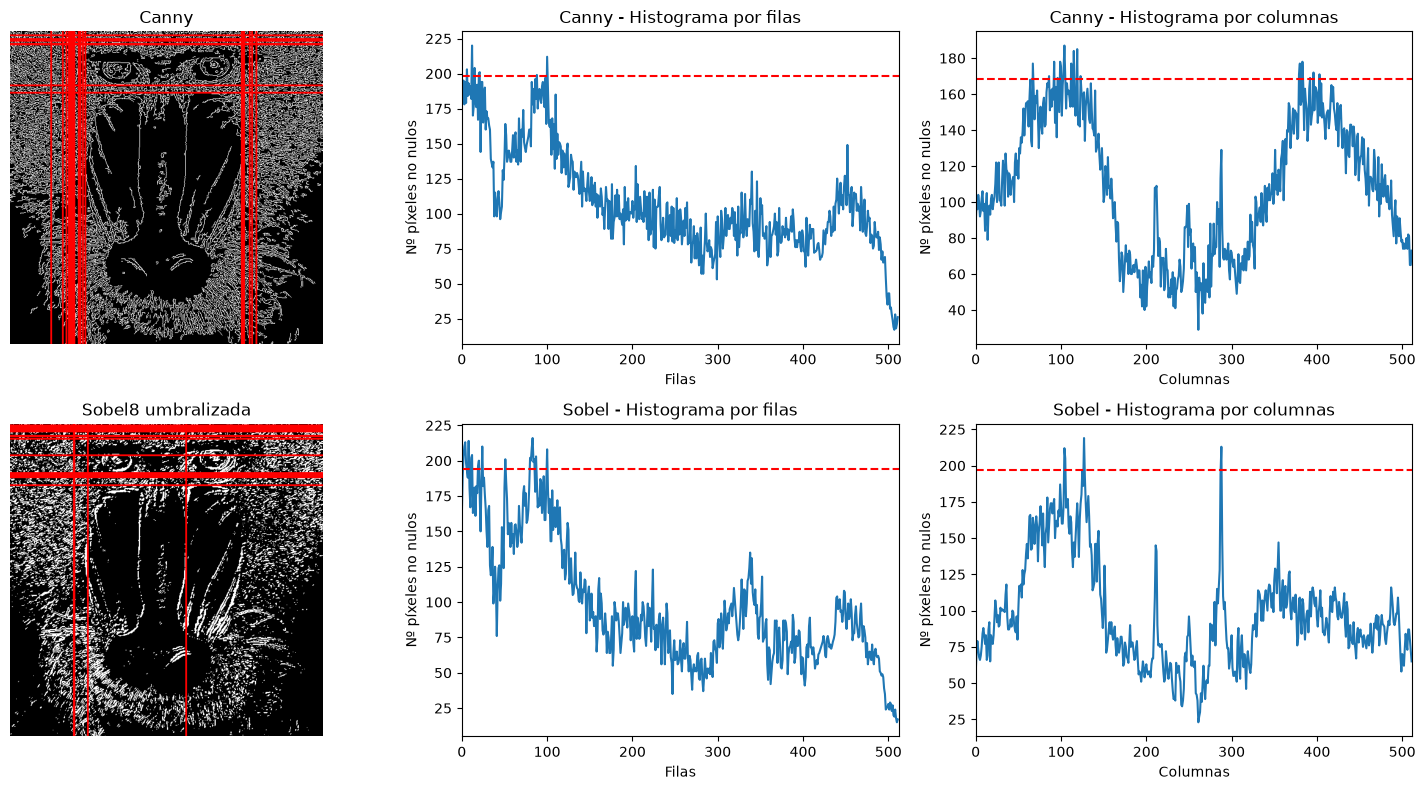

In [15]:
"""
    CANNY
"""

canny = cv2.Canny(gris, 100, 200)

row_counts_canny = cv2.reduce(
    canny, 1, cv2.REDUCE_SUM, dtype=cv2.CV_32SC1
)
rows_canny = row_counts_canny.flatten() / 255

col_counts_canny = cv2.reduce(
    canny, 0, cv2.REDUCE_SUM, dtype=cv2.CV_32SC1
)
cols_canny = col_counts_canny[0] / 255

maxfil_canny = max(rows_canny)
maxcol_canny = max(cols_canny)

fil90_canny = 0.90 * maxfil_canny
col90_canny = 0.90 * maxcol_canny

wp90_canny_row = []
for i in range(len(rows_canny)):
    if rows_canny[i] >= fil90_canny:
        wp90_canny_row.append((i, rows_canny[i]))

wp90_canny_col = []
for i in range(len(cols_canny)):
    if cols_canny[i] >= col90_canny:
        wp90_canny_col.append((i, cols_canny[i]))


"""
    SOBEL 8 UMBRALIZADA
"""

ggris = cv2.GaussianBlur(gris, (3, 3), 0)
sobelx = cv2.Sobel(ggris, cv2.CV_64F, 1, 0)  # x
sobely = cv2.Sobel(ggris, cv2.CV_64F, 0, 1)  # y
sobel = cv2.add(sobelx, sobely)
sobel8 = cv2.convertScaleAbs(sobel)

umbral = 100
_, sobel8Umbralizada = cv2.threshold(sobel8, umbral, 255, cv2.THRESH_BINARY)

row_counts_sobel = cv2.reduce(
    sobel8Umbralizada, 1, cv2.REDUCE_SUM, dtype=cv2.CV_32SC1
)
rows_sobel = row_counts_sobel.flatten() / 255

col_counts_sobel = cv2.reduce(
    sobel8Umbralizada, 0, cv2.REDUCE_SUM, dtype=cv2.CV_32SC1
)
cols_sobel = col_counts_sobel[0] / 255

maxfil_sobel = max(rows_sobel)
maxcol_sobel = max(cols_sobel)

fil90_sobel = 0.90 * maxfil_sobel
col90_sobel = 0.90 * maxcol_sobel

wp90_sobel8u_row = []
for i in range(len(rows_sobel)):
    if rows_sobel[i] >= fil90_sobel:
        wp90_sobel8u_row.append((i, rows_sobel[i]))

wp90_sobel8u_col = []
for i in range(len(cols_sobel)):
    if cols_sobel[i] >= col90_sobel:
        wp90_sobel8u_col.append((i, cols_sobel[i]))



"""
    IMÁGENES CON LAS FILAS Y COLUMNAS MARCADAS
"""

# CANNY
canny_marcada = cv2.cvtColor(canny, cv2.COLOR_GRAY2BGR)

height, width = canny.shape

for y, value in wp90_canny_row:
    cv2.line(
        canny_marcada,
        (0, y),
        (width - 1, y),
        (0, 0, 255),
        2
    )

for x, value in wp90_canny_col:
    cv2.line(
        canny_marcada,
        (x, 0),
        (x, height - 1),
        (0, 0, 255),
        2
    )


# SOBEL
sobel_marcada = cv2.cvtColor(sobel8Umbralizada, cv2.COLOR_GRAY2BGR)

height, width = sobel8Umbralizada.shape

for y, value in wp90_sobel8u_row:
    cv2.line(
        sobel_marcada,
        (0, y),
        (width - 1, y),
        (0, 0, 255),
        2
    )

for x, value in wp90_sobel8u_col:
    cv2.line(
        sobel_marcada,
        (x, 0),
        (x, height - 1),
        (0, 0, 255),
        2
    )

"""
    PLOT 2x3
"""

plt.figure(figsize=(15, 8))

# ---------------- CANNY ----------------

# Imagen
plt.subplot(2, 3, 1)
plt.title("Canny")
plt.axis("off")
plt.imshow(cv2.cvtColor(canny_marcada, cv2.COLOR_BGR2RGB))


# Histograma por filas
plt.subplot(2, 3, 2)
plt.title("Canny - Histograma por filas")
plt.xlabel("Filas")
plt.ylabel("Nº píxeles no nulos")
plt.plot(rows_canny)
plt.axhline(
    y=fil90_canny,
    color="r",
    linestyle="--",
    label="90% máximo"
)
plt.xlim([0, canny.shape[0]])


# Histograma por columnas
plt.subplot(2, 3, 3)
plt.title("Canny - Histograma por columnas")
plt.xlabel("Columnas")
plt.ylabel("Nº píxeles no nulos")
plt.plot(cols_canny)
plt.axhline(
    y=col90_canny,
    color="r",
    linestyle="--",
    label="90% máximo"
)
plt.xlim([0, canny.shape[1]])


# ---------------- SOBEL ----------------

# Imagen
plt.subplot(2, 3, 4)
plt.title("Sobel8 umbralizada")
plt.axis("off")
plt.imshow(cv2.cvtColor(sobel_marcada, cv2.COLOR_BGR2RGB))


# Histograma por filas
plt.subplot(2, 3, 5)
plt.title("Sobel - Histograma por filas")
plt.xlabel("Filas")
plt.ylabel("Nº píxeles no nulos")
plt.plot(rows_sobel)
plt.axhline(
    y=fil90_sobel,
    color="r",
    linestyle="--",
    label="90% máximo"
)
plt.xlim([0, sobel8Umbralizada.shape[0]])


# Histograma por columnas
plt.subplot(2, 3, 6)
plt.title("Sobel - Histograma por columnas")
plt.xlabel("Columnas")
plt.ylabel("Nº píxeles no nulos")
plt.plot(cols_sobel)
plt.axhline(
    y=col90_sobel,
    color="r",
    linestyle="--",
    label="90% máximo"
)
plt.xlim([0, sobel8Umbralizada.shape[1]])


plt.tight_layout()
plt.savefig("images/tarea2.png", dpi=300, bbox_inches="tight")
plt.show()


TAREA 3: Plantear reinterpretación de la parte de procesamiento de la imagen.
Idea: Substacción de fondo + píxeles variantes (movimiento) en lo que no es fondo.

In [23]:
vid = cv2.VideoCapture(0)

eliminadorFondo = cv2.createBackgroundSubtractorMOG2(history=100, varThreshold=50, detectShadows=False)

# Frames iniciales para que el modelo aprenda el fondo
for i in range(100):
    ret, frame = vid.read()
    eliminadorFondo.apply(frame)

first_frame_flag = 0

while(True):      
    ret, frame = vid.read()

    if ret:
        # Aplica efecto espejo sobre la entrada
        framem=cv2.flip(frame, 1)

        if first_frame_flag == 0:
            first_frame_flag = 1
        else:
            dif = cv2.absdiff(frame, pframe)
            dif_gris = cv2.cvtColor(dif, cv2.COLOR_BGR2GRAY)

            cv2.imshow('Diferencia', dif_gris)

            objetos = eliminadorFondo.apply(frame, learningRate=0)

            """     # debug para encontrar valores de intervalos
            dif_persona = dif_gris[objetos == 255]

            if len(dif_persona) > 0:
                print(
                    "min:", dif_persona.min(), "\n",
                    "max:", dif_persona.max(), "\n",
                    "mean:", dif_persona.mean(), "\n"
                )
            """

            color = np.zeros_like(frame)

            color[(objetos == 255) & (dif_gris < 10)] = (0, 255, 0) # lento -> verde
            color[(objetos == 255) & (dif_gris >= 10) & (dif_gris < 45)] = (0, 215, 255) # medio -> amarillo
            color[(objetos == 255) & (dif_gris >= 45)] = (0, 0, 255) # rapido -> rojo

            factor = 0.15
            redimensionada = cv2.resize(
                color,
                (0, 0),
                fx=factor,
                fy=factor
            )

            pixelada = cv2.resize(
                redimensionada,
                (frame.shape[1], frame.shape[0]),
                interpolation=cv2.INTER_NEAREST
            )

            # Mostrar resultado
            cv2.imshow('Pixeles foreground', pixelada)

        pframe = frame.copy()
   
    # Detenemos pulsado ESC
    if cv2.waitKey(20) == 27:
        break
  
# Libera el objeto de captura
vid.release()
# Destruye ventanas
cv2.destroyAllWindows()